# <a href="https://girafe.ai/" target="_blank" rel="noopener noreferrer"><img src="https://raw.githubusercontent.com/girafe-ai/ml-course/7096a5df4cada5ee651be1e3215c2f7fb8a7e0bf/logo_margin.svg" alt="girafe-ai logo" width="150px" align="left"></a> [ml-basic course](https://github.com/girafe-ai/ml-course) <a class="tocSkip">


# Lab assignment 01
## Data preprocessing, model training and evaluation

This lab assignment consists of several parts.

In this part you are supposed to work with tabular data: make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions in a chat, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

## 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [58]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [59]:
import ucimlrepo as uci
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

from sklearn.model_selection import train_test_split

In [60]:
dataset = uci.fetch_ucirepo(id=149)

print(dataset.metadata.name, '\n')
print(dataset.metadata.abstract, '\n')
print(dataset.metadata.additional_info.summary, '\n')

Statlog (Vehicle Silhouettes) 

3D objects within a 2D image by application of an ensemble of shape feature extractors to the 2D silhouettes of the objects. 

The purpose is to classify a given silhouette as one of four types of vehicle, using  a set of features extracted from the silhouette. The vehicle may be viewed from one of many different angles.  

HISTORY:

This data was originally gathered at the TI in 1986-87 by JP Siebert. It was partially financed by Barr and Stroud Ltd. The original purpose was to find a method of distinguishing 3D objects within a 2D image by application of an ensemble of shape feature extractors to the 2D silhouettes of the objects. Measures of shape features extracted from example silhouettes of objects to be discriminated were used to generate a classification rule tree by means of computer induction.

This object recognition strategy was successfully used to discriminate between silhouettes of model cars, vans and buses viewed from constrained elevati

In [61]:
data = dataset.data.features
target = dataset.data.targets

print(data.shape, target.shape)

(846, 18) (846, 1)


### 1.1 Data integrity

Check if data is valid. If it is not, remove invalid parts.


In [62]:
# we take the signs and the target from the dataset
feature_df = dataset.data.features.copy()
target_df = dataset.data.targets.copy()

# gluing it into one dataframe
df = pd.concat([feature_df, target_df], axis=1)
print("Shape before cleaning:", df.shape)

df = df.replace([np.inf, -np.inf], np.nan)

# we look at where NaN is and how many of them (amount)
print("NaNs per column:",)
print(df.isna().sum())

# deleting the lines that contain NaN
df = df.dropna()

# deleting duplicate lines
df = df.drop_duplicates()

print("Shape after cleaning:", df.shape)

# final data after cleaning (copies to avoid warnings)
feature_df = df[feature_df.columns].copy()
target_df = df[target_df.columns].copy() 

Shape before cleaning: (846, 19)
NaNs per column:
COMPACTNESS                         1
CIRCULARITY                         0
DISTANCE CIRCULARITY                0
RADIUS RATIO                        0
PR.AXIS ASPECT RATIO                0
MAX.LENGTH ASPECT RATIO             0
SCATTER RATIO                       0
ELONGATEDNESS                       0
PR.AXIS RECTANGULARITY              0
MAX.LENGTH RECTANGULARITY           0
SCALED VARIANCE ALONG MAJOR AXIS    0
SCALED VARIANCE ALONG MINOR AXIS    0
SCALED RADIUS OF GYRATION           0
SKEWNESS ABOUT MAJOR AXIS           0
SKEWNESS ABOUT MINOR AXIS           0
KURTOSIS ABOUT MINOR AXIS           0
KURTOSIS ABOUT MAJOR AXIS           0
HOLLOWS RATIO                       0
class                               0
dtype: int64
Shape after cleaning: (845, 19)


in "COMPACTNESS" found Nan and remove it

### 1.2 Train and test sets

Split data into 2 groups using `sklearn`'s infrastructure.

Which size of test set to choose?

In [63]:
X = feature_df
y = target_df['class'] # one-dimensional array

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size=0.2, 
    random_state=42,
    stratify=y # save class proportions
)

In [64]:
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(676, 18) (676,) (169, 18) (169,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [65]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,COMPACTNESS,CIRCULARITY,DISTANCE CIRCULARITY,RADIUS RATIO,PR.AXIS ASPECT RATIO,MAX.LENGTH ASPECT RATIO,SCATTER RATIO,ELONGATEDNESS,PR.AXIS RECTANGULARITY,MAX.LENGTH RECTANGULARITY,SCALED VARIANCE ALONG MAJOR AXIS,SCALED VARIANCE ALONG MINOR AXIS,SCALED RADIUS OF GYRATION,SKEWNESS ABOUT MAJOR AXIS,SKEWNESS ABOUT MINOR AXIS,KURTOSIS ABOUT MINOR AXIS,KURTOSIS ABOUT MAJOR AXIS,HOLLOWS RATIO
200,93.0,47,85,163,66,11,156,44,20,158,172,355,178,74,7,15,183,195
396,108.0,57,106,177,51,5,256,26,28,170,285,966,261,87,11,2,182,181
309,109.0,48,107,215,62,10,205,32,23,158,222,624,168,65,9,32,195,206
86,89.0,41,84,141,58,9,149,45,19,145,172,330,162,72,4,18,188,200
635,97.0,41,62,133,56,7,130,52,18,143,158,247,157,78,5,7,184,186
246,95.0,36,73,191,73,6,156,41,19,126,184,374,124,71,2,19,199,204
782,87.0,44,98,211,70,10,189,35,22,141,214,535,178,71,2,21,187,194
539,109.0,55,96,191,57,6,241,28,26,170,267,857,242,85,8,9,184,184
698,83.0,42,71,152,64,7,149,45,19,142,172,331,158,74,2,2,184,190
794,87.0,41,76,165,67,7,148,45,19,140,171,327,152,72,7,13,188,195


Methods `describe` and `info` deliver some useful information.

In [66]:
X_train_pd.describe()

,COMPACTNESS,CIRCULARITY,DISTANCE CIRCULARITY,RADIUS RATIO,PR.AXIS ASPECT RATIO,MAX.LENGTH ASPECT RATIO,SCATTER RATIO,ELONGATEDNESS,PR.AXIS RECTANGULARITY,MAX.LENGTH RECTANGULARITY,SCALED VARIANCE ALONG MAJOR AXIS,SCALED VARIANCE ALONG MINOR AXIS,SCALED RADIUS OF GYRATION,SKEWNESS ABOUT MAJOR AXIS,SKEWNESS ABOUT MINOR AXIS,KURTOSIS ABOUT MINOR AXIS,KURTOSIS ABOUT MAJOR AXIS,HOLLOWS RATIO
count,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000
mean,93.353550,44.788462,81.789941,168.440828,61.741124,8.693787,168.115385,41.106509,20.526627,147.902367,188.020710,435.831361,174.437870,72.576923,6.322485,12.321006,188.809172,195.534024
std,8.214937,6.119156,15.678160,33.935814,8.345653,5.024623,32.876717,7.760520,2.568908,14.480411,30.910904,174.266015,32.083742,7.707140,4.872857,8.982893,6.168064,7.425304
min,73.000000,33.000000,40.000000,104.000000,47.000000,3.000000,112.000000,26.000000,17.000000,118.000000,130.000000,184.000000,112.000000,59.000000,0.000000,0.000000,176.000000,181.000000
25%,87.000000,40.000000,70.000000,140.000000,57.000000,7.000000,146.000000,33.000000,19.000000,137.000000,167.000000,317.000000,150.000000,68.000000,2.000000,5.000000,184.000000,190.750000
50%,92.000000,44.000000,79.000000,166.000000,61.000000,8.000000,156.000000,43.000000,19.000000,146.000000,177.500000,360.500000,173.000000,72.000000,6.000000,11.000000,188.000000,197.000000
75%,99.000000,49.000000,96.500000,194.000000,65.000000,10.000000,197.000000,46.000000,23.000000,159.000000,217.000000,583.250000,198.000000,76.000000,9.000000,18.000000,193.000000,201.000000
max,119.000000,59.000000,112.000000,333.000000,138.000000,55.000000,265.000000,61.000000,29.000000,186.000000,320.000000,1018.000000,268.000000,135.000000,22.000000,41.000000,206.000000,211.000000


In [67]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
Index: 676 entries, 200 to 656
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   COMPACTNESS                       676 non-null    float64
 1   CIRCULARITY                       676 non-null    int64  
 2   DISTANCE CIRCULARITY              676 non-null    int64  
 3   RADIUS RATIO                      676 non-null    int64  
 4   PR.AXIS ASPECT RATIO              676 non-null    int64  
 5   MAX.LENGTH ASPECT RATIO           676 non-null    int64  
 6   SCATTER RATIO                     676 non-null    int64  
 7   ELONGATEDNESS                     676 non-null    int64  
 8   PR.AXIS RECTANGULARITY            676 non-null    int64  
 9   MAX.LENGTH RECTANGULARITY         676 non-null    int64  
 10  SCALED VARIANCE ALONG MAJOR AXIS  676 non-null    int64  
 11  SCALED VARIANCE ALONG MINOR AXIS  676 non-null    int64  
 12  SCALED RADI

## 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

### 2.0. Data preprocessing

Apply transformations to the dataset (if necessary).

Briefly explain the transformations

In [68]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(X_train) # fit only on train data to avoid data leakage
X_train_scaled = scaler.transform(X_train) 
X_test_scaled = scaler.transform(X_test)

# save the dataframes structure
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

Since the data has already been cleared of NaN and categorical variables are missing, as we saw in the previous steps, the main step of preprocessing is scaling.   

   The scaler.fit step is applicable only to the train sample, because if we apply it to the full dataset, data leakage will occur and information about the test sample will leak into the pipeline.


### 2.1. Basic logistic regression

* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression:\
`multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

In [69]:

from sklearn.linear_model import LogisticRegression

In [70]:
MyLogReg = LogisticRegression(
    tol=1e-3, 
    solver='saga', 
    max_iter=500,  
    multi_class='multinomial', 
    random_state=42
)

MyLogReg.fit(X_train_scaled, y_train)

c:\Users\n.tulupov\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


,penalty,'l2'
,dual,False
,tol,0.001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'saga'
,max_iter,500
,multi_class,'multinomial'


In [71]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=MyLogReg,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
)

# grid will train the required number of copies of the MyLogReg model by itself
grid.fit(X_train_scaled, y_train) 

best_logreg_C = grid.best_params_['C']
print(f"best_logreg_C={best_logreg_C}") 

print(grid.best_score_) # the best mean cross-validated score

best_logreg = grid.best_estimator_ # model with the best parameters 

best_logreg_C=10
0.7910693371887623


c:\Users\n.tulupov\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [72]:
from sklearn.metrics import accuracy_score, f1_score

y_pred = best_logreg.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", acc)
print("F1-macro:", f1)  

accuracy: 0.8402366863905325
F1-macro: 0.8371524841260252


In [73]:
%pip install scikit-plot


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


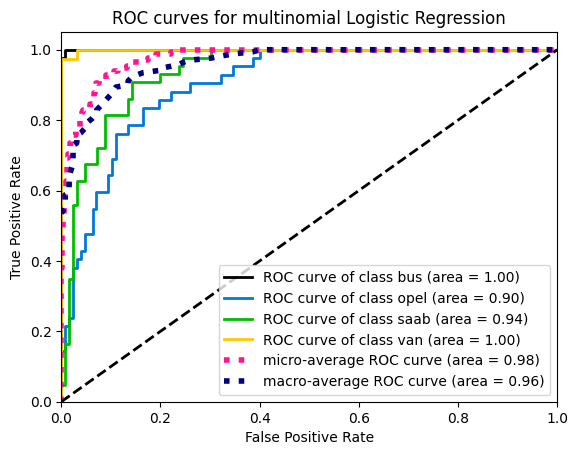

In [74]:

# adding the missing interp function to scipy
scipy.interp = np.interp

import scikitplot as skplt


y_proba = best_logreg.predict_proba(X_test_scaled)

skplt.metrics.plot_roc(y_test, y_proba)
plt.title("ROC curves for multinomial Logistic Regression")
plt.show()

The ROC curves show that the multinomial logistic regression model does a good job of this task.
For bus and van classes, the ROC curves (black and yellow) are almost perfectly aligned with the upper-left corner, which means that the model can almost perfectly separate these classes from others.   

For two car classes (opel and saab), the ROC curves are slightly lower, with AUC values of 0.90 and 0.94, respectively. This corresponds to the description from the information about the dataset: the silhouettes of the two cars are much more similar to each other, so it is more difficult for the classifier to distinguish them, which leads to a greater coincidence and a decrease in the percentage of true predictions.     

The dotted diagonal black line corresponds to a random classifier (AUC = 0.5). All ROC curves belonging to a particular class lie well above this baseline, which confirms that the model recognizes a meaningful data structure.    

micro-average AUC ≈ 0.98 - we take all classes without separation and calculate the TP-FP metrics for all predictions and build a ROC curve
macro-average AUC ≈ 0.96 - for each class, we calculate its metrics and then simply average them over all classes (each class gives the same class), it is just noticeable that there are classes that reduce the average quality

### 2.2. PCA: explained variance plot

Apply the PCA to the train part of the data.

Build the explaided variance plot.

In [75]:
from sklearn.decomposition import PCA
MyPCA = PCA(n_components=X_train_scaled.shape[1])  
MyPCA.fit(X_train_scaled)

,n_components,18
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


Let's take all the available signs to begin with.

In [76]:
explained_var = MyPCA.explained_variance_ratio_ # the proportion of variance of each component
cum_explained_var = np.cumsum(explained_var)   

for i, v in enumerate(np.cumsum(MyPCA.explained_variance_ratio_), start=1):
    print(i, v)

1 0.5233807999672248
2 0.6871054891421287
3 0.7990859499809903
4 0.865386690463728
5 0.9150334474385577
6 0.9438320386456582
7 0.9630866939187669
8 0.9750638881960131
9 0.9836733380574716
10 0.9888171863384463
11 0.9925107780969672
12 0.9949978056905301
13 0.9969409385639916
14 0.9981044325563652
15 0.9989294977011601
16 0.9996235972810714
17 0.9999793329744341
18 0.9999999999999999


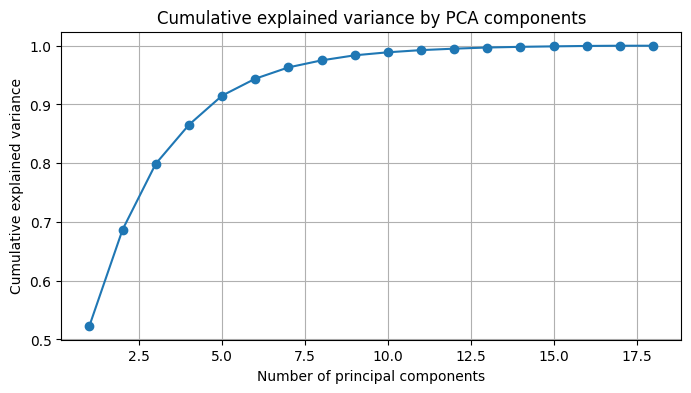

In [77]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_explained_var) + 1), cum_explained_var, marker='o')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.grid(True)
plt.title('Cumulative explained variance by PCA components')
plt.show()


The PCA graph shows that the cumulative explained variance grows rapidly and then begins to increase. From about 5-7 main components, we already get more than 90% of the total variance, while each of the other components contributes only a very small fraction.  

In many practical applications, it is considered sufficient to preserve about 90-95% of the variance: additional components already simulate noise and add complexity, without giving a proportional increase in the amount of information.

Therefore, in the next step, we will reduce the dimension from 18 initial objects to a smaller number of main components, for example, to 5, which will preserve most of the information about the data, while simplifying the model and improving its generalization.

### 2.3. PCA trasformation

Select the appropriate number of components.

Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train`, `val` and `test` parts.*

We have significantly reduced the number of features (from 18 to 7), while retaining most of the data variability.

In [78]:
n_components_min = 7
MyPCA_n = PCA(n_components=n_components_min)  
MyPCA_n.fit(X_train_scaled)

,n_components,7
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


Reducing the number of signs. Each new feature is a linear combination of the old ones.;

In [79]:
X_train_pca = MyPCA_n.transform(X_train_scaled)
X_test_pca = MyPCA_n.transform(X_test_scaled)

print(X_train_pca.shape, X_test_pca.shape)

(676, 7) (169, 7)


PCA is sensitive to the scale of objects, so the data must be standardized before applying PCA. In this experiment, PCA is compared with standardized training data (X_train_scaled), and the same scaling is applied to the test data.

In [80]:
print(np.cumsum(MyPCA_n.explained_variance_ratio_)[-1])

0.9630866939187669


The last element of the cumulative sum array - the sum of all components - is greater than 0.9, which means that there are enough features.

Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.

### 2.4. Logistic regression on PCA-preprocessed data

* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.
* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression:\
`multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

In [81]:
MyLogReg_PCA = LogisticRegression(
    tol=1e-3, 
    solver='saga', 
    max_iter=500,  
    multi_class='multinomial', 
    random_state=42
)

In [82]:

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=MyLogReg_PCA,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
)

grid.fit(X_train_pca, y_train) 

best_logreg_pca_C = grid.best_params_['C']
print(best_logreg_pca_C) 

print(grid.best_params_) 
print(grid.best_score_) 

best_logreg = grid.best_estimator_ 


10
{'C': 10}
0.6243378591251193


c:\Users\n.tulupov\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [83]:

y_pred = best_logreg.predict(X_test_pca)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", acc)
print("F1-macro:", f1)  

accuracy: 0.6331360946745562
F1-macro: 0.6302744182387638


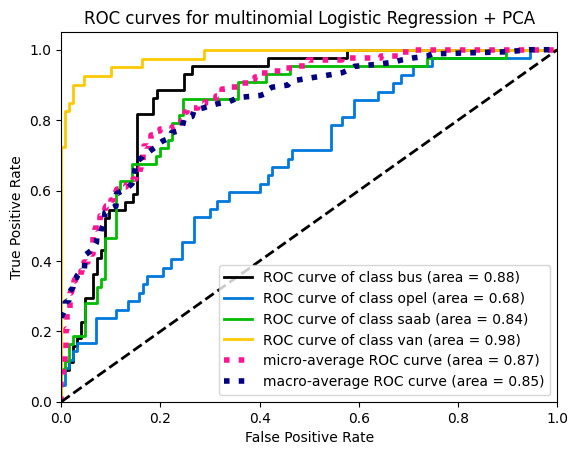

In [84]:
y_proba = best_logreg.predict_proba(X_test_pca)

skplt.metrics.plot_roc(y_test, y_proba)
plt.title("ROC curves for multinomial Logistic Regression + PCA")
plt.show()

After applying PCA with 7 components (which account for about 96% of the total variance), the performance of the logistic regression model deteriorates markedly: the accuracy drops from ~0.84 to ~0.63, and the macro F1 indicator shows a similar decrease.
This illustrates an important limitation of PCA.: it preserves the directions with the greatest variance, but these directions are not necessarily the most distinguishable for the classification task. Low-variance components that have been discarded may still contain information that is crucial for separating the most similar classes (there are two types of cars in this dataset).
Therefore, in this particular task, PCA does not improve the classifier and actually degrades its performance.

In [85]:
from sklearn.pipeline import Pipeline

logreg_pca_pipe = Pipeline([
    ('scaler', StandardScaler()),          
    ('pca', PCA(n_components=n_components_min)),          
    ('model', LogisticRegression(          
        tol=1e-3,
        solver='saga',
        max_iter=500,
        multi_class='multinomial',
        random_state=42
    ))
])

In [86]:
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100]   # C относится к шагу 'clf'
}

grid_pipe_pca = GridSearchCV(
    estimator=logreg_pca_pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
)

grid_pipe_pca.fit(X_train_pca, y_train)

print("Best params:", grid_pipe_pca.best_params_)
print("Best CV f1_macro:", grid_pipe_pca.best_score_)

Best params: {'model__C': 10}
Best CV f1_macro: 0.621844063720257


c:\Users\n.tulupov\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


accuracy: 0.6331360946745562
F1-macro: 0.6302744182387638


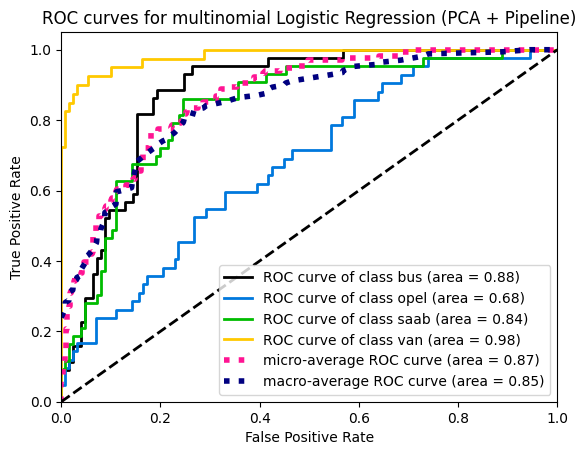

In [87]:
best_pipe = grid_pipe_pca.best_estimator_

y_pred = best_pipe.predict(X_test_pca)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", acc)
print("F1-macro:", f1)

y_proba = best_pipe.predict_proba(X_test_pca)

skplt.metrics.plot_roc(y_test, y_proba)
plt.title("ROC curves for multinomial Logistic Regression (PCA + Pipeline)")
plt.show()


### 2.5. Decision tree

* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [88]:
from sklearn.tree import DecisionTreeClassifier


tree_pipe = Pipeline([
    ('scaler', StandardScaler()),          
    ('model', DecisionTreeClassifier(
        criterion='gini', 
        max_depth=5,
        random_state=42
    ))
])

In [89]:
param_grid = {
    'model__max_depth': [i for i in range(1, 20)]   
}

grid_pipe_tree = GridSearchCV(
    estimator=tree_pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    n_jobs=-1,
)

grid_pipe_tree.fit(X_train_scaled, y_train)

best_depth = grid_pipe_tree.best_params_['model__max_depth']

print("Best params:", grid_pipe_tree.best_params_)
print("Best CV f1_macro:", grid_pipe_tree.best_score_)

Best params: {'model__max_depth': 10}
Best CV f1_macro: 0.709844808399724


accuracy: 0.6923076923076923
F1-macro: 0.6957044246370089


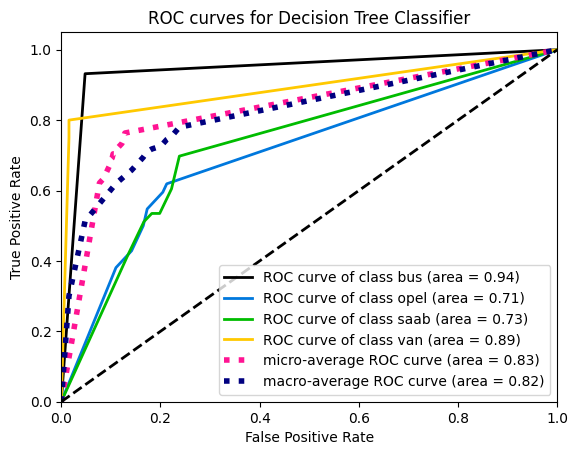

In [90]:
best_pipe = grid_pipe_tree.best_estimator_

y_pred = best_pipe.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", acc)
print("F1-macro:", f1)

y_proba = best_pipe.predict_proba(X_test_scaled)

skplt.metrics.plot_roc(y_test, y_proba)
plt.title("ROC curves for Decision Tree Classifier")
plt.show()


let's try to find the optimal parameters for DecisionTree using the **min_samples_leaf** parameter as well

In [91]:
param_grid = {
    'model__max_depth': [i for i in range(2, 25)],
    'model__min_samples_leaf': [1, 2, 5, 10],
    'model__criterion': ['gini', 'entropy', 'log_loss']
}


grid_pipe_tree = GridSearchCV(
    estimator=tree_pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    n_jobs=-1,
)

grid_pipe_tree.fit(X_train_scaled, y_train)

best_depth = grid_pipe_tree.best_params_['model__max_depth']

print("Best params:", grid_pipe_tree.best_params_)
print("Best CV f1_macro:", grid_pipe_tree.best_score_)

Best params: {'model__criterion': 'gini', 'model__max_depth': 9, 'model__min_samples_leaf': 2}
Best CV f1_macro: 0.7125913620798414


accuracy: 0.7159763313609467
F1-macro: 0.7174641167562351


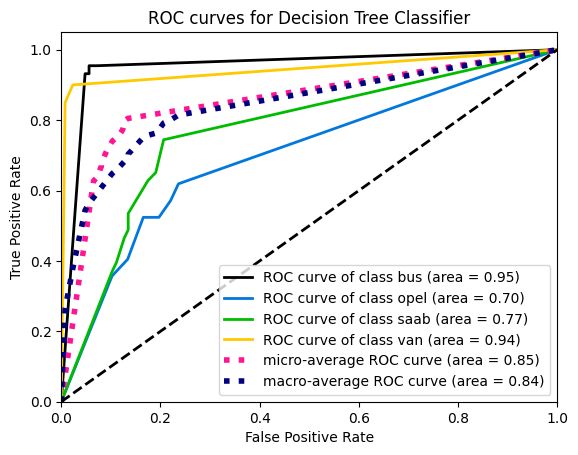

In [92]:
best_pipe = grid_pipe_tree.best_estimator_

y_pred = best_pipe.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", acc)
print("F1-macro:", f1)

y_proba = best_pipe.predict_proba(X_test_scaled)

skplt.metrics.plot_roc(y_test, y_proba)
plt.title("ROC curves for Decision Tree Classifier")
plt.show()


The customized decision tree (`max_depth = 9`, `min_samples_leaf = 2`) provides an accuracy of about 0.72, and the F1 macro provides about 0.72 on the test set, which is still worse than with simple logistic regression without PCA (accuracy 0.84, F1 macro 0.84). This suggests that the class boundaries in this dataset are relatively close to linear, so a linear classifier is a very good fit, while a single decision tree that approximates the boundaries by axis splits cannot use strong non-linearity here and mainly adds variance.

### 2.6. Bagging

Here starts the ensembling part. You need to use [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html)

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ with step 5.

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble?

In [93]:
from sklearn.ensemble import BaggingClassifier

base_logreg = LogisticRegression(
    C=best_logreg_C,              # find earlier
    solver='saga',
    max_iter=500,
    multi_class='multinomial',
    random_state=42
)

base_tree = DecisionTreeClassifier(
    criterion='gini',
    max_depth=9,
    min_samples_leaf=2,
    random_state=42
)

base_tree_free = DecisionTreeClassifier(
    criterion='gini',
    max_depth=25,
    min_samples_leaf=1,
    random_state=42
)


In [94]:
acc_logreg_static = []
f1_logreg_static = []

acc_tree_static = []
f1_tree_static = []

acc_tree_free_static = []
f1_tree_free_static = []

n_list = list(range(2, 100, 5))

for n_estimator_i in n_list:

    bag_logreg = BaggingClassifier(
        estimator=base_logreg,   
        n_estimators=n_estimator_i,         # ensemble size
        bootstrap=True,          
        n_jobs=-1,               
        random_state=42
    )
        
    bag_logreg.fit(X_train_scaled, y_train)
    y_pred = bag_logreg.predict(X_test_scaled)

    acc_logreg = accuracy_score(y_test, y_pred)
    f1_logreg = f1_score(y_test, y_pred, average='macro')
    acc_logreg_static.append(acc_logreg)
    f1_logreg_static.append(f1_logreg)

    print(f"logreg N={n_estimator_i} accuracy:{acc_logreg} F1-macro: {f1_logreg}")

    bag_tree = BaggingClassifier(
        estimator=base_tree,    
        n_estimators=n_estimator_i,
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    )

    bag_tree.fit(X_train_scaled, y_train)
    y_pred = bag_tree.predict(X_test_scaled)

    acc_tree = accuracy_score(y_test, y_pred)
    acc_tree_static.append(acc_tree)
    f1_tree = f1_score(y_test, y_pred, average='macro')
    f1_tree_static.append(f1_tree)

    print(f"tree N={n_estimator_i} accuracy:{acc_tree} F1-macro: {f1_tree}") 


    bag_tree_free = BaggingClassifier(
        estimator=base_tree_free,    
        n_estimators=n_estimator_i,
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    )

    bag_tree_free.fit(X_train_scaled, y_train)
    y_pred = bag_tree_free.predict(X_test_scaled)

    acc_tree_free = accuracy_score(y_test, y_pred)
    acc_tree_free_static.append(acc_tree_free)
    f1_tree_free = f1_score(y_test, y_pred, average='macro')
    f1_tree_free_static.append(f1_tree_free)

    print(f"tree free N={n_estimator_i} accuracy:{acc_tree_free} F1-macro: {f1_tree_free}") 




print("LogReg Bagging best accuracy:", max(acc_logreg_static))
print("Decision Tree Bagging best accuracy:", max(acc_tree_static))
print("Decision Tree deep Bagging best accuracy:", max(acc_tree_free_static))

logreg N=2 accuracy:0.8284023668639053 F1-macro: 0.8220592070944184
tree N=2 accuracy:0.6923076923076923 F1-macro: 0.6911240401853668
tree free N=2 accuracy:0.6390532544378699 F1-macro: 0.6375556319412812
logreg N=7 accuracy:0.834319526627219 F1-macro: 0.8282321417955447
tree N=7 accuracy:0.7396449704142012 F1-macro: 0.7386677838290742
tree free N=7 accuracy:0.7100591715976331 F1-macro: 0.7105719962572417
logreg N=12 accuracy:0.834319526627219 F1-macro: 0.8295359966708281
tree N=12 accuracy:0.7633136094674556 F1-macro: 0.7602808208193718
tree free N=12 accuracy:0.7633136094674556 F1-macro: 0.7630804770551962
logreg N=17 accuracy:0.8402366863905325 F1-macro: 0.8355027942656807
tree N=17 accuracy:0.7633136094674556 F1-macro: 0.7607327476241335
tree free N=17 accuracy:0.7692307692307693 F1-macro: 0.7659431087484729
logreg N=22 accuracy:0.834319526627219 F1-macro: 0.8295359966708281
tree N=22 accuracy:0.7633136094674556 F1-macro: 0.7568420398467034
tree free N=22 accuracy:0.775147928994082

20 20 20 20
20 20 20 20


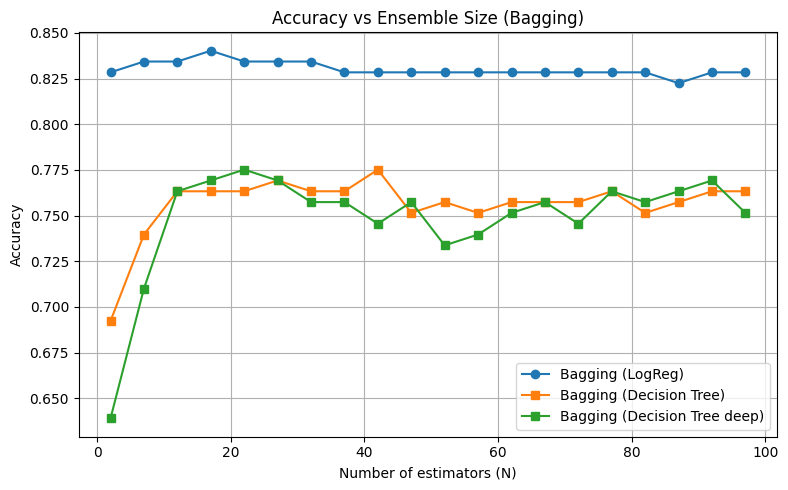

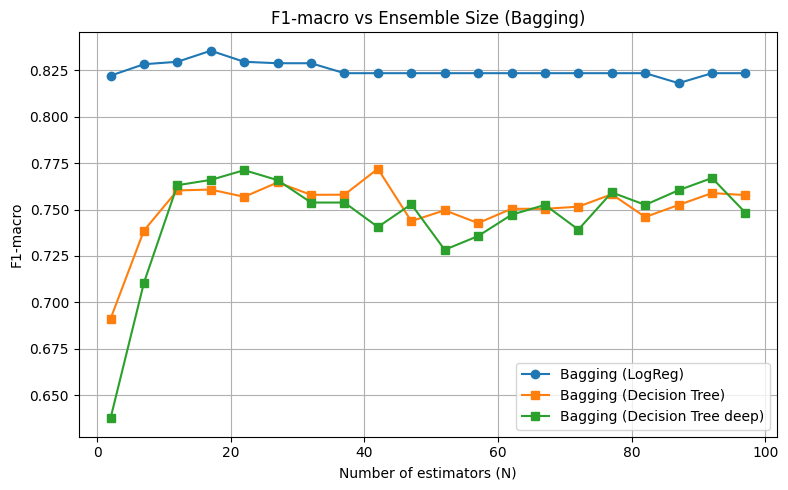

In [95]:
print(len(n_list), len(acc_logreg_static), len(acc_tree_static), len(acc_tree_free_static))
print(len(n_list), len(f1_logreg_static), len(f1_tree_static), len(f1_tree_free_static))

# accuracy plot
plt.figure(figsize=(8, 5))
plt.plot(n_list, acc_logreg_static, marker='o', label='Bagging (LogReg)')
plt.plot(n_list, acc_tree_static, marker='s', label='Bagging (Decision Tree)')
plt.plot(n_list, acc_tree_free_static, marker='s', label='Bagging (Decision Tree deep)')
plt.xlabel('Number of estimators (N)')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Ensemble Size (Bagging)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# F1-macro plot
plt.figure(figsize=(8, 5))
plt.plot(n_list, f1_logreg_static, marker='o', label='Bagging (LogReg)')
plt.plot(n_list, f1_tree_static, marker='s', label='Bagging (Decision Tree)')
plt.plot(n_list, f1_tree_free_static, marker='s', label='Bagging (Decision Tree deep)')
plt.xlabel('Number of estimators (N)')
plt.ylabel('F1-macro')
plt.title('F1-macro vs Ensemble Size (Bagging)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

To check whether the hyperparameters found in version 2.5 are optimal for the trees in the package set, we compared the two basic trainees:

- “ordered” value (`max_depth = 9`, `min_samples_leaf = 2`);
- “deep” tree (`max_depth = 25`, `min_samples_leaf = 1`).

For each of them, we have created sets of packages with a different number of ratings. The accuracy obtained and the F1-macro curves are very close, and the best test accuracy for both variants is about 0.775. Deeper, less ordered trees do not provide any noticeable improvement, and sometimes even deteriorate slightly with small ensemble sizes.

This suggests that for this particular dataset and its separation, hyperparameters configured for a single decision tree already work quite well in a set of packages. However, as a rule, trees used as the base trees for studying in batch or random forests are more difficult to choose than a single tree, since averaging reduces variance and can compensate for a higher degree of retraining of individual trees.

### 2.7. Random Forest

Now we will work with the [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

* Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

In [96]:
from sklearn.ensemble import RandomForestClassifier

acc_rf_list = []
f1_rf_list = []

n_trees_list = list(range(10, 201, 10))  # кол-во деревьев от 10 до 200

for n_trees in n_trees_list:
    rf = RandomForestClassifier(
        n_estimators=n_trees,
        criterion='gini',
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    )
    
    rf.fit(X_train_scaled, y_train)
    y_pred = rf.predict(X_test_scaled)
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')
    
    acc_rf_list.append(acc)
    f1_rf_list.append(f1)
    
    print(f"Random Forest N={n_trees} accuracy: {acc} F1-macro: {f1}")

Random Forest N=10 accuracy: 0.727810650887574 F1-macro: 0.7240919936373278
Random Forest N=20 accuracy: 0.7751479289940828 F1-macro: 0.7709151161786607
Random Forest N=30 accuracy: 0.7514792899408284 F1-macro: 0.7467842062141552
Random Forest N=40 accuracy: 0.7692307692307693 F1-macro: 0.7634248754522955
Random Forest N=50 accuracy: 0.7633136094674556 F1-macro: 0.7593979868370112
Random Forest N=60 accuracy: 0.7633136094674556 F1-macro: 0.7606441639574169
Random Forest N=70 accuracy: 0.7514792899408284 F1-macro: 0.7448527626991484
Random Forest N=80 accuracy: 0.7514792899408284 F1-macro: 0.7488588016204295
Random Forest N=90 accuracy: 0.7455621301775148 F1-macro: 0.7412199127315406
Random Forest N=100 accuracy: 0.7455621301775148 F1-macro: 0.7398663285205931
Random Forest N=110 accuracy: 0.7396449704142012 F1-macro: 0.7353675373283216
Random Forest N=120 accuracy: 0.7514792899408284 F1-macro: 0.7474227297756709
Random Forest N=130 accuracy: 0.7455621301775148 F1-macro: 0.7412199127315

In [97]:
# поиск лучшего N по accuracy и F1
best_acc = max(acc_rf_list)
best_acc_idx = acc_rf_list.index(best_acc)
best_acc_n = n_trees_list[best_acc_idx]

best_f1 = max(f1_rf_list)
best_f1_idx = f1_rf_list.index(best_f1)
best_f1_n = n_trees_list[best_f1_idx]

print("\nBest accuracy:", best_acc, "at N =", best_acc_n)
print("Best F1-macro:", best_f1, "at N =", best_f1_n)


Best accuracy: 0.7751479289940828 at N = 20
Best F1-macro: 0.7709151161786607 at N = 20


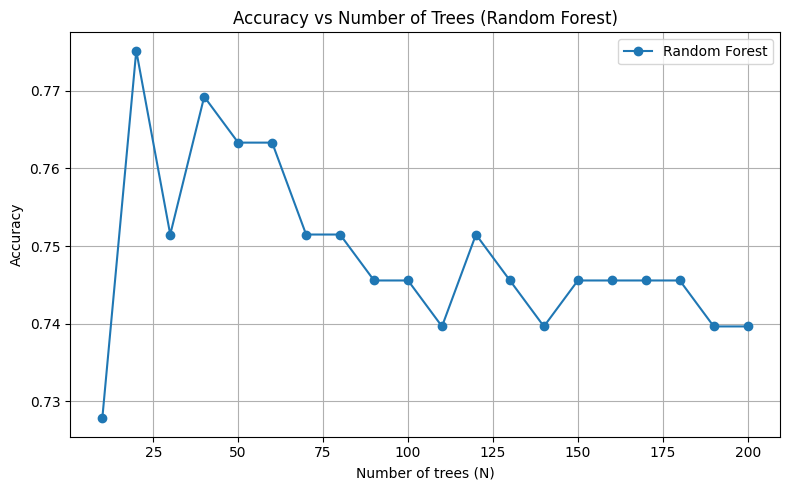

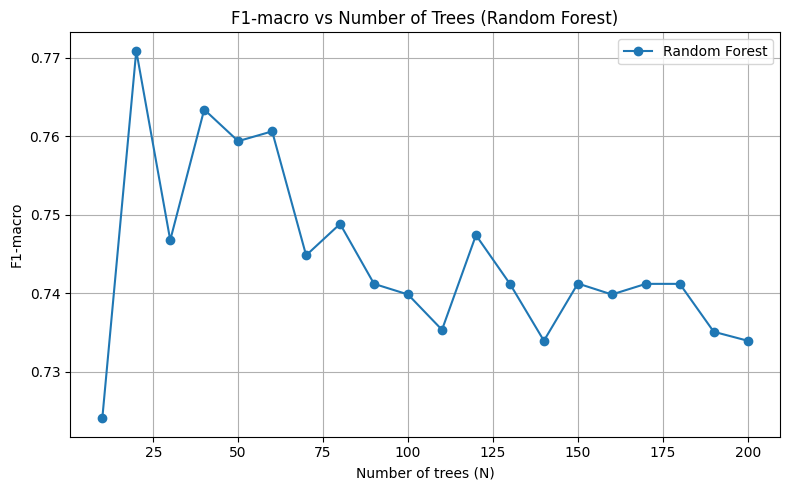

In [98]:
# accuracy plot
plt.figure(figsize=(8, 5))
plt.plot(n_trees_list, acc_rf_list, marker='o', label='Random Forest')
plt.xlabel('Number of trees (N)')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Number of Trees (Random Forest)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# F1-macro plot
plt.figure(figsize=(8, 5))
plt.plot(n_trees_list, f1_rf_list, marker='o', label='Random Forest')
plt.xlabel('Number of trees (N)')
plt.ylabel('F1-macro')
plt.title('F1-macro vs Number of Trees (Random Forest)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

For a random forest, the best test performance is achieved using approximately **20 trees.**  
(accuracy ≈ 0.775, F1-macro ≈ 0.771). After that, both accuracy and F1 will not get higher, so adding more trees will not lead to systematic improvement.

In 2.6, the optimal ensemble sizes were slightly different: for the best set of logistic
regressions, about 15 models were used (although just one logistic regression shows almost the same result), while for the best set of decision trees, about
40 trees to achieve an accuracy of ≈0.775. Thus, a random forest achieves
maximum quality with fewer trees than with a conventional set of decision trees, due
to additional randomness in the selection of features that decorrelates the trees. However, in
this dataset, all tree ensembles (packetization and random forest) still perform worse than
one well-tuned logistic regression, which indicates that class boundaries
are close to linear and complex tree models do not bring significant benefits.

### 2.8. Learning curve

Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected. First train it on first part, then on first and second parts combined (so the train size in increased by 2 times), first 3 parts and so on.

* You may use `sklearn`'s [readymade function](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html). But note that you need to adjust parameters of this function appropriately.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score vs dataset size).

* Analyse the final plot. Can you make any conlusions using it?

In [99]:
# Mix the train and split it into 10 parts
n_train = X_train_scaled.shape[0]
n_splits = 10

rng = np.random.RandomState(42)
indices = rng.permutation(n_train)

X_train_shuffled = X_train_scaled.iloc[indices]
y_train_shuffled = y_train.iloc[indices]

In [100]:
# Lists for sample sizes and metrics
train_sizes = []

acc_logreg_curve = []
f1_logreg_curve = []

acc_tree_curve = []
f1_tree_curve = []

acc_rf_curve = []
f1_rf_curve = []

In [101]:
# Cycle by 1/10, 2/10, ..., 10/10 train data

for k in range(1, n_splits + 1):
    end = (n_train // n_splits) * k if k < n_splits else n_train
    
    X_train_k = X_train_shuffled[:end]
    y_train_k = y_train_shuffled[:end]
    
    train_sizes.append(len(X_train_k))
    print(f"\nTrain size step {k}: {len(X_train_k)} samples")

    # Logistic Regression
    logreg = LogisticRegression(
        C=10,
        solver='saga',
        max_iter=2000,
        # multi_class='multinomial', # we'll remove it so that there are no warnings
        random_state=42
    )
    logreg.fit(X_train_k, y_train_k)
    y_pred_logreg = logreg.predict(X_test_scaled)

    acc_l = accuracy_score(y_test, y_pred_logreg)
    f1_l = f1_score(y_test, y_pred_logreg, average='macro')
    acc_logreg_curve.append(acc_l)
    f1_logreg_curve.append(f1_l)
    print(f"  LogReg        accuracy: {acc_l:.4f}  F1-macro: {f1_l:.4f}")

    # Decision Tree
    tree = DecisionTreeClassifier(
        criterion='gini',
        max_depth=9,
        min_samples_leaf=2,
        random_state=42
    )
    tree.fit(X_train_k, y_train_k)
    y_pred_tree = tree.predict(X_test_scaled)

    acc_t = accuracy_score(y_test, y_pred_tree)
    f1_t = f1_score(y_test, y_pred_tree, average='macro')
    acc_tree_curve.append(acc_t)
    f1_tree_curve.append(f1_t)
    print(f"  Tree          accuracy: {acc_t:.4f}  F1-macro: {f1_t:.4f}")

    # Random Forest
    rf = RandomForestClassifier(
        n_estimators=20,
        criterion='gini',
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    )
    rf.fit(X_train_k, y_train_k)
    y_pred_rf = rf.predict(X_test_scaled)

    acc_r = accuracy_score(y_test, y_pred_rf)
    f1_r = f1_score(y_test, y_pred_rf, average='macro')
    acc_rf_curve.append(acc_r)
    f1_rf_curve.append(f1_r)
    print(f"  RandomForest  accuracy: {acc_r:.4f}  F1-macro: {f1_r:.4f}")



Train size step 1: 67 samples
  LogReg        accuracy: 0.7337  F1-macro: 0.7343
  Tree          accuracy: 0.5089  F1-macro: 0.5147
  RandomForest  accuracy: 0.6627  F1-macro: 0.6590

Train size step 2: 134 samples
  LogReg        accuracy: 0.7515  F1-macro: 0.7584
  Tree          accuracy: 0.6627  F1-macro: 0.6634
  RandomForest  accuracy: 0.6746  F1-macro: 0.6749

Train size step 3: 201 samples
  LogReg        accuracy: 0.8107  F1-macro: 0.8097
  Tree          accuracy: 0.6627  F1-macro: 0.6673
  RandomForest  accuracy: 0.6627  F1-macro: 0.6577

Train size step 4: 268 samples
  LogReg        accuracy: 0.8284  F1-macro: 0.8285
  Tree          accuracy: 0.6391  F1-macro: 0.6459
  RandomForest  accuracy: 0.7160  F1-macro: 0.7075

Train size step 5: 335 samples
  LogReg        accuracy: 0.8225  F1-macro: 0.8233
  Tree          accuracy: 0.6923  F1-macro: 0.6976
  RandomForest  accuracy: 0.6746  F1-macro: 0.6636

Train size step 6: 402 samples
  LogReg        accuracy: 0.8462  F1-macro: 

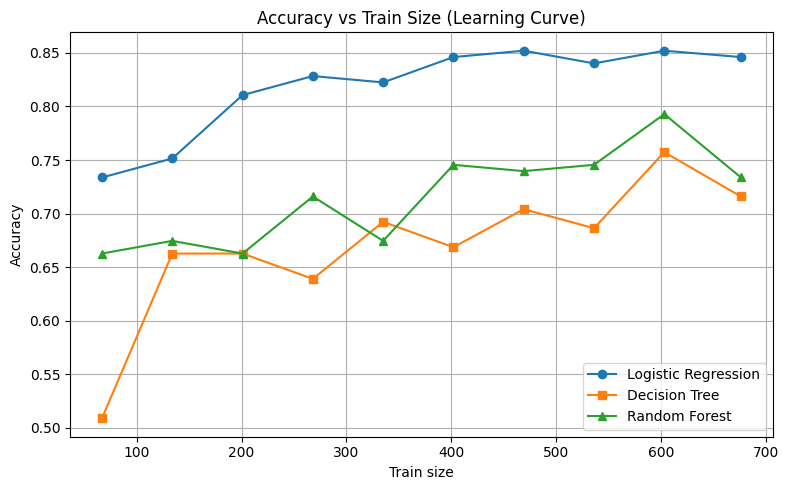

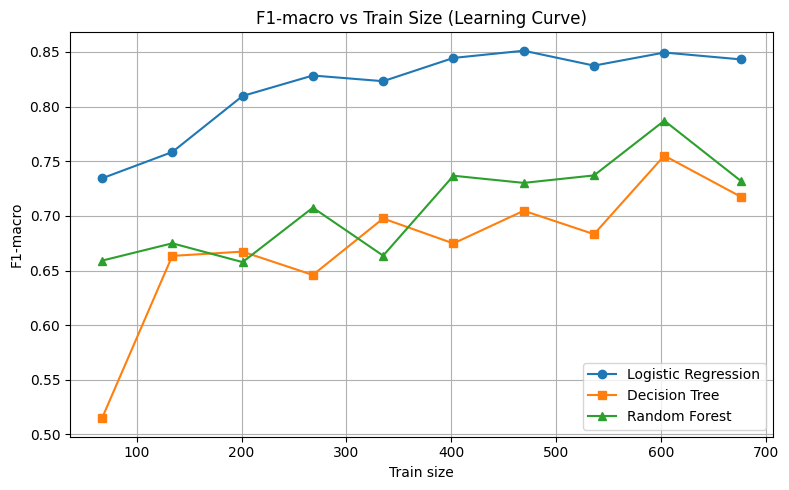

In [102]:
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, acc_logreg_curve, marker='o', label='Logistic Regression')
plt.plot(train_sizes, acc_tree_curve, marker='s', label='Decision Tree')
plt.plot(train_sizes, acc_rf_curve, marker='^', label='Random Forest')
plt.xlabel('Train size')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Train Size (Learning Curve)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, f1_logreg_curve, marker='o', label='Logistic Regression')
plt.plot(train_sizes, f1_tree_curve, marker='s', label='Decision Tree')
plt.plot(train_sizes, f1_rf_curve, marker='^', label='Random Forest')
plt.xlabel('Train size')
plt.ylabel('F1-macro')
plt.title('F1-macro vs Train Size (Learning Curve)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

The learning curves show that all three models benefit from increasing the training set size: both accuracy and F1-macro systematically grow as we add more data. However, their behavior is quite different.   
- Logistic Regression dominates across all train sizes. Its performance improves quickly on the first few chunks of data and then stabilizes around 0.84–0.85 in accuracy and F1-macro. This suggests that the decision boundary in this task is close to linear and that the model has relatively low variance: even with a moderate amount of data it already generalizes well, and adding more samples only gives small gains.   
- The single Decision Tree starts with very low scores on small train sizes and shows the largest fluctuations, which indicates high variance and sensitivity to the particular training subset. As the train size grows, the tree becomes more stable and reaches around 0.71–0.76 in accuracy/F1 on the full dataset, but it still clearly underperforms Logistic Regression.   
- Random Forest behaves in between these two extremes. It is consistently better and more stable than a single tree, especially for medium and large train sizes, thanks to averaging over many trees. Nevertheless, even with the full training set it remains slightly below Logistic Regression. This again supports the conclusion that the underlying class boundaries are mostly linear, so tree-based models (even ensembles) cannot fully close the gap to the linear classifier on this dataset.



### 2.9. Boosting

Apply [GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) to this problem.

Find optimal hyperparameters using [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) or RandomizedSearchCV.

Hyperparameters to consider:
* depth of each tree
* number of decision trees
* learning rate

In [105]:
from sklearn.ensemble import GradientBoostingClassifier

gb_clf = GradientBoostingClassifier(random_state=42)

param_grid_gb = {
    'n_estimators': [50, 100, 150, 200, 300],
    'max_depth': [1, 2, 3, 4],
    'learning_rate': [0.01, 0.05, 0.1, 0.2]
}

grid_gb = GridSearchCV(
    estimator=gb_clf,
    param_grid=param_grid_gb,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
)

Best params (Gradient Boosting): {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 300}
Best CV f1_macro (Gradient Boosting): 0.7681917965744087
Gradient Boosting test accuracy: 0.757396449704142
Gradient Boosting test F1-macro: 0.7523359546761373


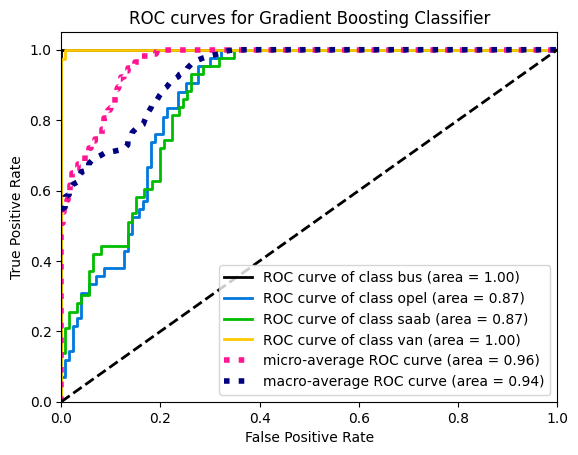

In [ ]:
grid_gb.fit(X_train_scaled, y_train)

print("Best params (Gradient Boosting):", grid_gb.best_params_)
print("Best CV f1_macro (Gradient Boosting):", grid_gb.best_score_)

# the best model for GB
best_gb = grid_gb.best_estimator_

# evaluation on the test set
y_pred_gb = best_gb.predict(X_test_scaled)

acc_gb = accuracy_score(y_test, y_pred_gb)
f1_gb = f1_score(y_test, y_pred_gb, average='macro')

print("Gradient Boosting test accuracy:", acc_gb)
print("Gradient Boosting test F1-macro:", f1_gb)


# ROC curves for Gradient Boosting
y_proba_gb = best_gb.predict_proba(X_test_scaled)

skplt.metrics.plot_roc(y_test, y_proba_gb)
plt.title("ROC curves for Gradient Boosting Classifier")
plt.show()

GradientBoostingClassifier with hyperparameters `learning_rate = 0.2`, `max_depth = 3`, `n_estimators = 300` provides the best cross-validation of the F1 macro, which is about **0.77** . In the prepared test set, it achieves **accuracy of ≈ 0.76** and **F1 macro of ≈ 0.75**. This is clearly better than using a single decision tree, and comparable to other tree ensembles (packetization and random forest), but still noticeably worse than the best logistic regression model. The ROC curves (macro AUC ≈ 0.94) show that the increase provides a high degree of class probability ranking, however, its optimal decision boundary at the standard threshold value of 0.5 still does not match the performance of the linear classifier in this dataset.
markdown

### General conclusions

1. **Logistic regression (excluding PCA) is the most effective model.**  
   With adjusted regularization (`C = 10`), it achieves an accuracy of about **0,84** and ** 0.84 F1 macros ** on the test set, surpassing all tree models and ensembles. This indicates that the true decision boundary in this problem is close to linear, and a well-ordered linear classifier matches it very well.

2. **PCA reduces performance here.**  
   Reducing 18 features to 7 main components before performing logistic regression significantly degrades the quality (accuracy/F1 is approximately equal to **0.63** ). Although PCA retains most of the differences, some of the information needed to separate classes is lost, so controlled performance decreases.

3. **The unified decision tree is unstable and weaker than the linear model.**  
   Even after tuning (`max_depth = 9`, `min_samples_leaf = 2`), the tree reaches an accuracy of only about **0.72/F1** and shows high variance, especially on small training subsets.

4. **Ensembles of trees (bundling, random forest, boosting) significantly improve compared to a single tree, but do not exceed logistic regression.**
   - Grouping of trees and a random forest ensure the accuracy of testing approximately within **0.77** , which is clearly better than using a separate tree, and more stable due to the reduction of variance by averaging.  
   - Increasing the gradient with shallow trees also achieves an accuracy of /F1 about **0.75–0.77** and it shows a very high ROC AUC, but still remains below the linear model.

5. **Learning curves confirm these observations.**  
   As the size of the train increases, all models improve, but logistic regression remains consistently high and quickly becomes saturated, while tree-based methods require more data and never close the gap.

Overall, this lab work shows that ensembles of decision trees (packetization, random forest, gradient boosting) are powerful and reliable models, but for datasets with an almost linearly separable structure, a properly configured linear classifier may still be the best and easiest choice.